## 09 Explainability and Report

#### Purpose
- Explain **why** the final models flag a policy-year: which features drive claim risk and lapse risk, in which direction, and for individual policies.
- Show how the models would be **used** (retention targeting, pricing adequacy), state the **limitations**, and draw the **conclusions and recommendations** of the project.

#### Models explained
The final models of notebooks 06a/06b/07a/07b, as loaded by 08a/08b from `data/processed/models/`:

| Target | Models | Primary (from 08a) |
|---|---|---|
| Claim (`CLAIM_IN_TERM`) | logistic regression, random forest, XGBoost, LightGBM | XGBoost |
| Lapse (`LAPSE`) | logistic regression, random forest, XGBoost | random forest |

Everything is computed on the **validation years (OOT2, policy-years 2023 – Aug 2024)**, the holdout opened once in 08a/08b, so the explanations describe the models on data they never saw.

#### How we explain the models
| Tool | Question it answers | Models |
|---|---|---|
| **Permutation importance** | How much does the ranking (ROC-AUC) drop when one feature is shuffled? | every model, the same way |
| **Feature contributions (SHAP-style)** | For each policy, how much did each feature push the prediction up or down? `baseline + contributions = prediction` | XGBoost, LightGBM: exact TreeSHAP; random forest: tree path decomposition; logistic regression: coefficient × (value − average) |
| **Partial dependence** | How does the average prediction change when we set one feature to a value for every policy? | every model, the same way |

All three are computed with our own code in `src/explain.py` (no extra package): XGBoost and LightGBM compute their exact SHAP values themselves, and the other two methods are a few lines each. **Importance shows what a model relies on, not cause and effect.**

#### Steps
0. Setup: models, settings
1. Samples of the validation years
2. Global drivers: permutation importance and feature contributions for each model
3. Partial dependence for key features
4. Example explanations of individual policies
5. Business use: retention targeting (lapse) and pricing adequacy (claims)
6. Limitations and data caveats
7. Conclusions and recommendations

#### Authors
Organized and prepared by Sebastian Carino, Ma. Loisa Celorico, Cyrill Agustin, John Navarro, and Justino Rotairo III.

- **Date Created:** 2026-11-07
- **Date Modified:** 2026-11-18 (findings from the final run)

### Section 0. Load the libraries and working directory
Same setup as 08a/08b, so the notebook runs on every teammate's machine. Notebooks 08a and 08b must have run with `EVAL_SPLIT = "valid"` first: this notebook reads their predictions and results.

#### 0.1 Imports, paths, settings and the models

In [1]:
%load_ext autoreload
%autoreload 2

# Find the repo root from any folder, so `src` can be imported
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import json
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score

from src.paths import DOCS, PROCESSED, REPORTS, ensure_dirs
from src.db import connect
from src import evaluation as ev
from src import explain as ex

warnings.filterwarnings("ignore", category=FutureWarning)     # pandas downcasting notes from the saved preprocessing
pd.options.display.float_format = "{:,.4g}".format
ensure_dirs()

SEED = 42
SPLIT = "valid"                     # the holdout opened in 08a/08b (OOT2, 2023 - Aug 2024)
OUT = "explain_valid"               # prefix of every file saved here
OUT_DIR = REPORTS                   # tables and figures go to reports/
MODEL_DIR, PRED_DIR = PROCESSED / "models", PROCESSED / "predictions"

# Sample sizes (rows of the validation years). Larger = steadier, slower.
N_IMPORTANCE = {"claim": 100_000, "lapse": 50_000}   # permutation importance (Step 2.1); claims are rare, so more rows
N_CONTRIB = 3_000                   # feature contributions (Steps 2.2, 4.1)
N_PDP = 5_000                       # partial dependence (Step 3.1)

con = connect(db_path=None, memory_limit="6GB")
con.execute(f"CREATE OR REPLACE VIEW feats AS SELECT * FROM read_parquet('{PROCESSED / 'features.parquet'}')")

# The models and the primary model of each target, exactly as 08a used them
run_08a = json.loads((REPORTS / "eval_valid_08a_run.json").read_text())
assert run_08a["eval_split"] == "valid", "run 08a and 08b with EVAL_SPLIT = 'valid' first"
registry = {kind: ev.load_registry(kind, MODEL_DIR, REPORTS) for kind in ev.TARGETS}
PRIMARY = run_08a["primary"]
for kind in ev.TARGETS:
    assert set(registry[kind]) == set(run_08a["models"][kind]), f"{kind}: the models differ from 08a's run"
    print(f"{kind}: {list(registry[kind])}; primary {PRIMARY[kind]}")

# Short display names for tables and charts
NAMES = {"claim_baseline_logreg": "logistic regression", "claim_rf": "random forest", "claim_xgb": "XGBoost",
         "claim_lgbm": "LightGBM", "lapse_baseline_logreg": "logistic regression", "lapse_rf": "random forest",
         "lapse_xgb": "XGBoost"}
DEFINITION = pd.read_excel(DOCS / "feature_dictionary.xlsx").set_index("feature")["definition"].to_dict()

/opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


claim: ['claim_baseline_logreg', 'claim_lgbm', 'claim_rf', 'claim_xgb']; primary claim_xgb
lapse: ['lapse_baseline_logreg', 'lapse_rf', 'lapse_xgb']; primary lapse_rf


### Section 1. Load the final models and data

#### 1.1 A random sample of the validation years
One random sample per target (seed 42, the same rows every run), read straight from `features.parquet`. A sample is enough to explain the models; the business tables in Section 5 use **every** validation row (the predictions saved by 08a).

**Check:** the ROC-AUC of each model on the sample should be close to its ROC-AUC on all validation rows in 08a (Step 3.1 / 4.1). A large difference would mean the sample is not representative or a model was loaded differently.

In [2]:
# Step 1.1 Samples of the validation years and a check against 08a
SAMPLE, PRED_SAMPLE = {}, {}
bench = {kind: pd.read_csv(REPORTS / f"eval_valid_{kind}_benchmark_classification.csv") for kind in ev.TARGETS}
for kind in ev.TARGETS:
    t0 = time.time()
    raw, df = ex.load_sample(con, kind, registry[kind], SPLIT, N_IMPORTANCE[kind], seed=SEED)
    SAMPLE[kind] = raw
    PRED_SAMPLE[kind] = ex.predict_all(registry[kind], raw, df)
    full = bench[kind][bench[kind]["scope"].str.startswith("OOT2")].set_index("model")["roc_auc"]
    check = pd.DataFrame({"AUC on the sample": {n: roc_auc_score(raw["y"], p) for n, p in PRED_SAMPLE[kind].items()},
                          "AUC on all rows (08a)": full})
    print(f"{kind}: {len(raw):,} policy-years, {int(raw['y'].sum()):,} events ({raw['y'].mean():.2%}), "
          f"{time.time() - t0:.0f} s")
    display(check.dropna().style.format("{:.3f}"))

claim: 100,000 policy-years, 1,562 events (1.56%), 9 s


,AUC on the sample,AUC on all rows (08a)
claim_baseline_logreg,0.651,0.650
claim_lgbm,0.713,0.709
claim_rf,0.739,0.736
claim_xgb,0.674,0.669


lapse: 50,000 policy-years, 5,098 events (10.20%), 8 s


,AUC on the sample,AUC on all rows (08a)
lapse_baseline_logreg,0.607,0.615
lapse_rf,0.622,0.627
lapse_xgb,0.613,0.619


**What we found (Step 1.1):** the samples are representative: on 100,000 claim policy-years (1,562 claims, 1.56%) and 50,000 lapse policy-years (5,098 lapses, 10.2%), every model's ROC-AUC is within 0.008 of its AUC on all validation rows in 08a (for example, claim random forest 0.739 vs 0.736, lapse random forest 0.622 vs 0.627).

### Section 2. Global drivers

#### 2.1 Permutation importance for every model
For each feature we **shuffle its values** across the sampled policy-years (so it no longer carries any information about the policy) and measure how much the model's **ROC-AUC drops**:

$$\text{importance}(f) = \text{AUC} - \text{AUC}_{f\ \text{shuffled}}$$

A big drop means the model relies on that feature to rank policies. The same shuffled data go to every model, so the numbers are comparable **across models of the same target**. Features are shuffled in the raw rows and prepared again, so features derived from them follow (shuffling `tenure_years` also changes `new_business`). One shuffle per feature; differences below about 0.002 are noise.

This takes a few minutes per target.

claim: 52 features x 4 models in 2.3 min
lapse: 68 features x 3 models in 0.8 min


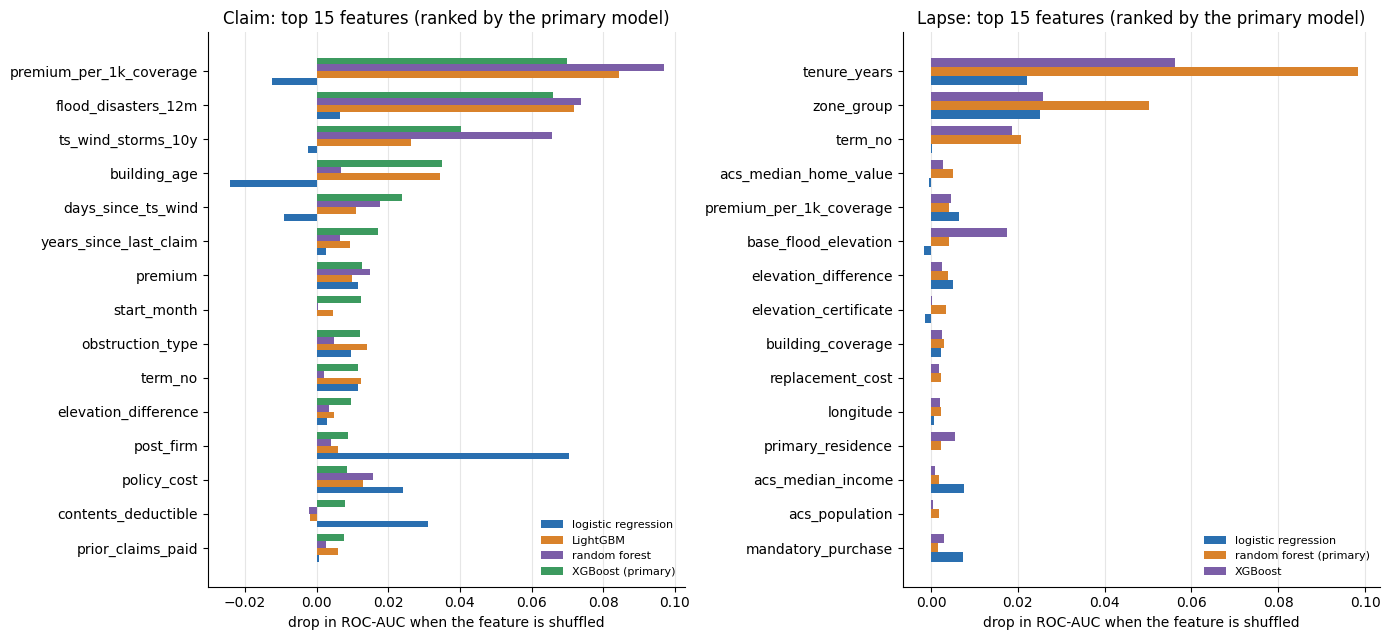


claim: top 10 features of each model


,logistic regression,LightGBM,random forest,XGBoost
rank,,,,
1,post_firm,premium_per_1k_coverage,premium_per_1k_coverage,premium_per_1k_coverage
2,max_wind_kt_10y,flood_disasters_12m,flood_disasters_12m,flood_disasters_12m
3,prev_gap_days,building_age,ts_wind_storms_10y,ts_wind_storms_10y
4,contents_deductible,ts_wind_storms_10y,max_wind_kt_10y,building_age
5,building_description,max_wind_kt_10y,days_since_flood_disaster,days_since_ts_wind
6,policy_cost,obstruction_type,days_since_ts_wind,years_since_last_claim
7,hurricane_wind_storms_10y,policy_cost,policy_cost,premium
8,prior_claims_n,term_no,premium,start_month
9,hfiaa_surcharge,days_since_ts_wind,hurricane_wind_per_year,obstruction_type



lapse: top 10 features of each model


,logistic regression,random forest,XGBoost
rank,,,
1,zone_group,tenure_years,tenure_years
2,tenure_years,zone_group,zone_group
3,elevated_building,term_no,term_no
4,acs_median_income,acs_median_home_value,base_flood_elevation
5,mandatory_purchase,premium_per_1k_coverage,hfiaa_surcharge
6,premium_per_1k_coverage,base_flood_elevation,primary_residence
7,acs_median_age,elevation_difference,premium_per_1k_coverage
8,latitude,elevation_certificate,latitude
9,elevation_difference,building_coverage,mandatory_purchase


In [3]:
# Step 2.1 Permutation importance (drop in ROC-AUC) on the validation sample, every model and feature
IMPORTANCE = {}
for kind in ev.TARGETS:
    t0 = time.time()
    imp = ex.permutation_importance(registry[kind], SAMPLE[kind], seed=SEED)
    IMPORTANCE[kind] = imp.sort_values(PRIMARY[kind], ascending=False)
    IMPORTANCE[kind].to_csv(OUT_DIR / f"{OUT}_{kind}_permutation_importance.csv")
    print(f"{kind}: {len(imp)} features x {imp.shape[1]} models in {(time.time() - t0) / 60:.1f} min")

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, kind in zip(axes, ev.TARGETS):
    top = IMPORTANCE[kind].head(15)[::-1]
    names = list(registry[kind])
    h = 0.8 / len(names)
    for i, name in enumerate(names):
        style = ev.model_style(name, i + 1)
        ax.barh(np.arange(len(top)) + i * h - 0.4 + h / 2, top[name].fillna(0), height=h,
                color=style["color"], label=NAMES[name] + (" (primary)" if name == PRIMARY[kind] else ""))
    ax.set_yticks(range(len(top)), top.index)
    ax.set(title=f"{kind.capitalize()}: top 15 features (ranked by the primary model)",
           xlabel="drop in ROC-AUC when the feature is shuffled")
    ax.legend(frameon=False, fontsize=8, loc="lower right")
    ev.style_axes(ax, grid="x")
plt.tight_layout()
plt.savefig(OUT_DIR / f"fig_{OUT}_permutation_importance.png", dpi=150)
plt.show()

# The top 10 of every model side by side (rank 1 = most important)
for kind in ev.TARGETS:
    ranks = pd.DataFrame({NAMES[n]: IMPORTANCE[kind][n].sort_values(ascending=False).head(10).index.tolist()
                          for n in registry[kind]}, index=pd.RangeIndex(1, 11, name="rank"))
    print(f"\n{kind}: top 10 features of each model")
    display(ranks)

**What we found (Step 2.1)**

*Claims*
1. **The tree models rank claims mainly with the price of cover and recent disasters:** shuffling `premium_per_1k_coverage` lowers the ROC-AUC by **0.07–0.10** and `flood_disasters_12m` (flood-related disaster declarations in the county in the last 12 months) by **0.07**, for all three tree models. Then come the storm-exposure features (`ts_wind_storms_10y`: 0.066 for the random forest, 0.04 for XGBoost) and `building_age` (0.03 for XGBoost and LightGBM).
2. A plausible reading of the price result: under **Risk Rating 2.0** (all validation policy-years), the price per $1,000 of cover is set with catastrophe models, so it carries a lot of flood-risk information that the trees can use. This is an interpretation, not something the data prove.
3. **The logistic regression relies on different features** (`post_firm` 0.071, `contents_deductible` 0.031, `policy_cost` 0.024) and **gets better** when some features are shuffled (`building_age` −0.024, `premium_per_1k_coverage` −0.012): the straight-line relationships it learned on 2014–2020 point the wrong way in 2023–24. This is one reason the trees rank better on the validation years.

*Lapse*

4. **Tenure and flood zone dominate, for all three models:** shuffling `tenure_years` lowers the AUC by **0.098** (random forest), 0.056 (XGBoost) and 0.022 (logistic regression); `zone_group` by 0.050, 0.026 and 0.025. `term_no` follows for the trees (0.02), `base_flood_elevation` for XGBoost (0.018) and `elevated_building` for the logistic regression (0.011). Every other feature costs the trees less than 0.007.
5. **Price change barely matters for ranking lapse:** `premium_change_pct` ranks 18th to 20th in every model (AUC drop about 0.001). Who lapses depends far more on **how long the policy has been held** and **where the property is** than on the latest premium change.

#### 2.2 Feature contributions (SHAP-style) for each model
Permutation importance says **how much** a model relies on a feature, but not in **which direction**. Feature contributions split each policy's prediction into a baseline plus one contribution per feature:

$$\text{prediction}_i = \text{baseline} + \sum_f \text{contribution}_{i,f}$$

| Model | Method | Scale |
|---|---|---|
| XGBoost, LightGBM | Exact **TreeSHAP**, computed by XGBoost / LightGBM themselves | log-odds |
| Random forest | **Path decomposition** (Saabas): at every split of every tree, the change in the probability is credited to the split's feature; averaged over the trees | probability |
| Logistic regression | **coefficient × (value − sample average)**, the exact SHAP value of a linear model | log-odds |

A category's levels and a feature's missing-value flag are added into the feature. In each chart, one dot is one policy-year; **red = high value of the feature, blue = low**; dots to the right push the risk up. Grey dots are categories (no high/low). The check below confirms that baseline + contributions = each model's own prediction.

**Direction table:** for each number feature, the correlation (Spearman) between its value and its contribution: **+** = a higher value raises the predicted risk, **−** = it lowers it.

claim logistic regression  log-odds      0.0 s; max |baseline + contributions - prediction| = 3.6e-16
claim LightGBM             log-odds     10.5 s; max |baseline + contributions - prediction| = 3.7e-14
claim random forest        probability   0.8 s; max |baseline + contributions - prediction| = 8.3e-17
claim XGBoost              log-odds      1.2 s; max |baseline + contributions - prediction| = 6.0e-07
lapse logistic regression  log-odds      0.0 s; max |baseline + contributions - prediction| = 3.3e-16
lapse random forest        probability   1.6 s; max |baseline + contributions - prediction| = 3.9e-16
lapse XGBoost              log-odds      0.2 s; max |baseline + contributions - prediction| = 3.0e-07


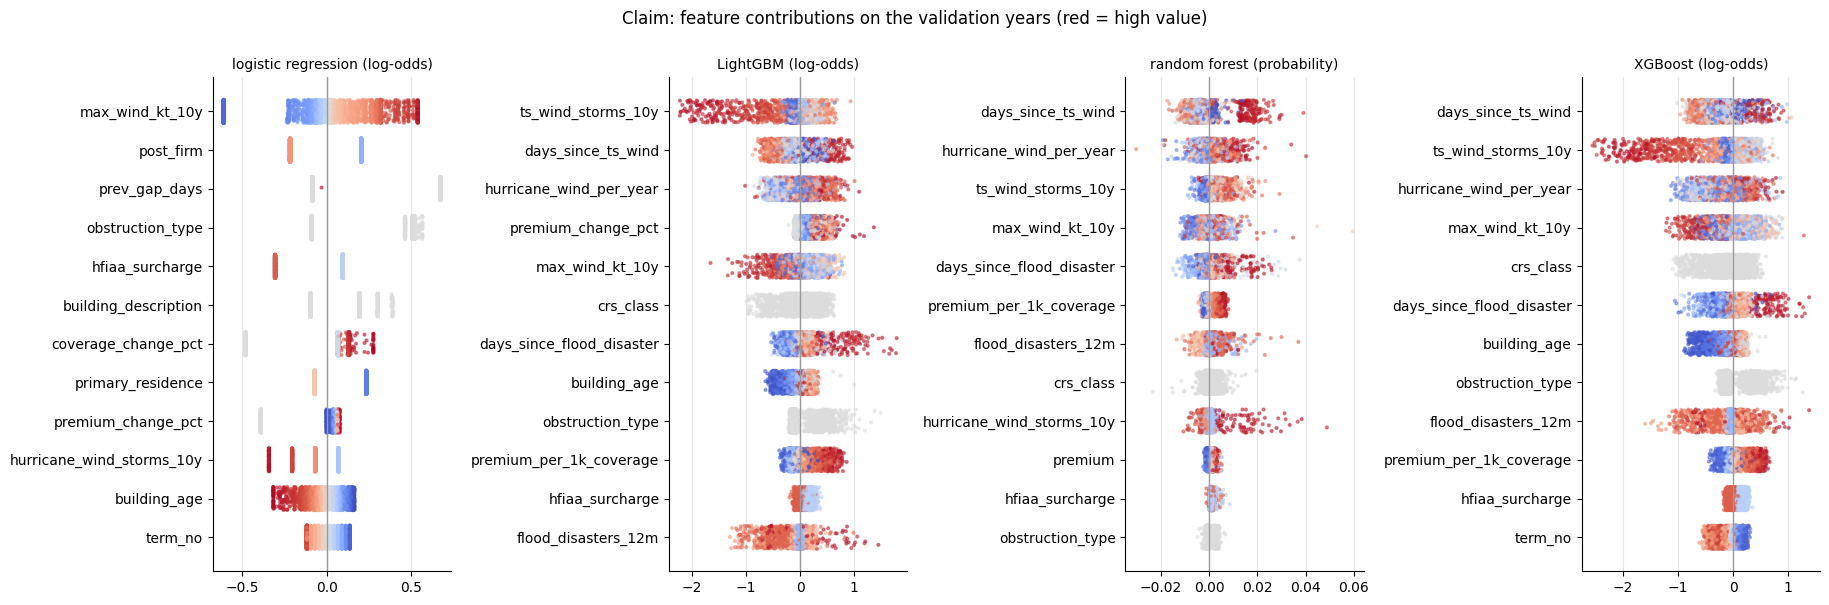

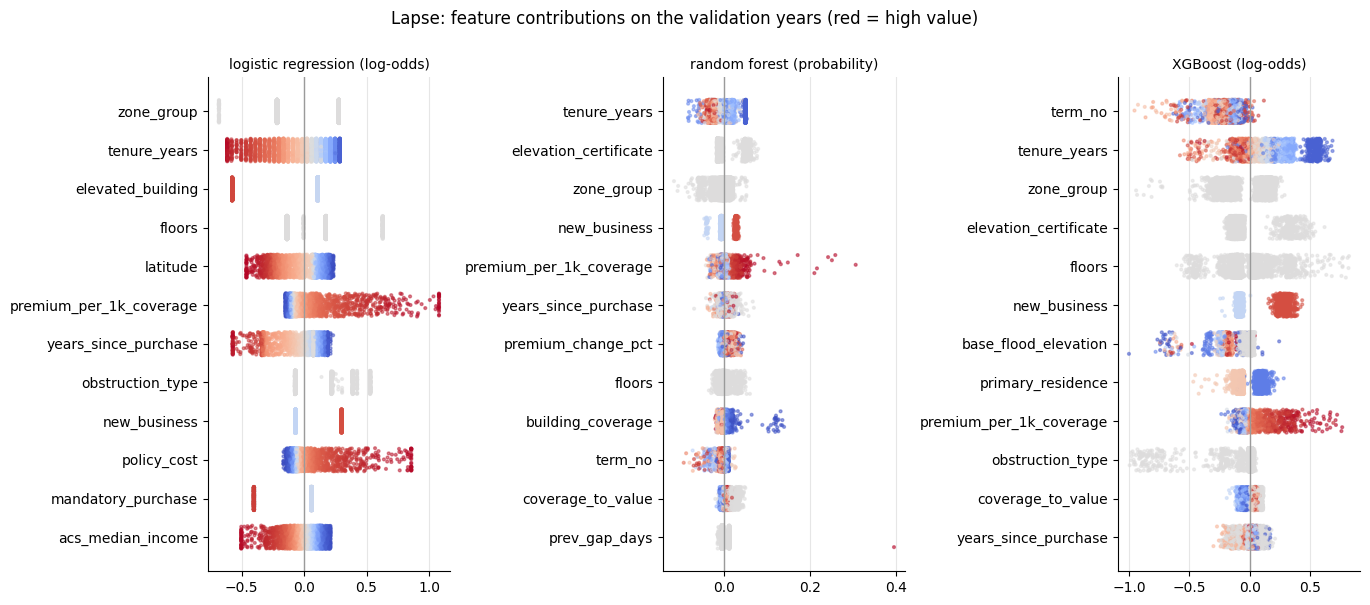


claim: top features by mean |contribution|, with direction


,model,feature,mean_abs_contribution,scale,direction,spearman,definition
45,XGBoost,days_since_ts_wind,0.3359,log-odds,-,-0.21,Days since the last 34+ kt wind at the cell; NULL = none since 1980
46,XGBoost,ts_wind_storms_10y,0.3221,log-odds,-,-0.20,Storms that brought tropical-storm-force wind (34+ kt) to the cell in the 10 years before the start
47,XGBoost,hurricane_wind_per_year,0.3187,log-odds,+,+0.19,"Long-run rate of 64+ kt storms at the cell per year, from 1980 to the start"
48,XGBoost,max_wind_kt_10y,0.2768,log-odds,-,-0.16,Highest estimated tropical-cyclone wind (knots) at the property's 0.1-degree cell in the 10 years before the start; 0 = none
49,XGBoost,crs_class,0.2063,log-odds,category,,Community Rating System class on the term (1 = best; NULL = not in CRS)
50,XGBoost,days_since_flood_disaster,0.1865,log-odds,+,+0.66,Days since the most recent flood-related declaration in the county or state
51,XGBoost,building_age,0.1781,log-odds,+,+0.57,Policy-year start year minus construction year
52,XGBoost,obstruction_type,0.1760,log-odds,category,,Obstruction type below the elevated floor
53,XGBoost,flood_disasters_12m,0.1477,log-odds,mixed,-0.07,Flood-related disaster declarations in the county (or statewide) in the 12 months before the start
54,XGBoost,premium_per_1k_coverage,0.1401,log-odds,+,+0.86,"Premium per $1,000 of building + contents coverage: the price of cover"



lapse: top features by mean |contribution|, with direction


,model,feature,mean_abs_contribution,scale,direction,spearman,definition
15,random forest,tenure_years,0.0217,probability,-,-0.81,Years from the original new-business date to the policy-year start
16,random forest,elevation_certificate,0.0172,probability,category,,Elevation certificate indicator code
17,random forest,zone_group,0.0117,probability,category,,"Rated flood zone group: A, V, X, D or UNKNOWN"
18,random forest,new_business,0.0108,probability,+,+0.68,First year of the policy (tenure below 1 year)
19,random forest,premium_per_1k_coverage,0.0088,probability,+,+0.26,"Premium per $1,000 of building + contents coverage: the price of cover"
20,random forest,years_since_purchase,0.0079,probability,+,+0.23,Years from the property purchase date to the start (NULL if the date is later or missing)
21,random forest,premium_change_pct,0.0075,probability,+,+0.52,Change in premium from the previous term of the same policy (%)
22,random forest,floors,0.0072,probability,category,,Number of floors code
23,random forest,building_coverage,0.0068,probability,-,-0.72,Building coverage ($)
24,random forest,term_no,0.0064,probability,-,-0.58,"Term number within the rebuilt policy, counting terms since the data begins (2009)"


In [4]:
# Step 2.2 Feature contributions on the first N_CONTRIB sampled rows, for every model
CONTRIB = {kind: {} for kind in ev.TARGETS}
for kind in ev.TARGETS:
    raw = SAMPLE[kind].iloc[:N_CONTRIB].reset_index(drop=True)
    df = ex.prepare(raw, registry[kind])
    for name, m in registry[kind].items():
        t0 = time.time()
        c, base, scale = ex.contributions(m, raw, df)
        total = ex.to_probability(base + c.sum(axis=1).to_numpy(), scale)
        CONTRIB[kind][name] = {"contrib": c, "base": base, "scale": scale, "pred": total, "raw": raw, "df": df}
        # check: the contributions add up to the model's own prediction on the same rows
        own = ev.predict({k: v for k, v in m.items() if k != "calibrator"}, df[m["features"]], raw)
        print(f"{kind} {NAMES[name]:20s} {scale:11s} {time.time() - t0:5.1f} s; "
              f"max |baseline + contributions - prediction| = {np.max(np.abs(total - own)):.1e}")

for kind in ev.TARGETS:
    names = list(registry[kind])
    fig, axes = plt.subplots(1, len(names), figsize=(4.6 * len(names), 6))
    for ax, name in zip(axes, names):
        r = CONTRIB[kind][name]
        ex.plot_beeswarm(ax, r["contrib"], r["df"], f"{NAMES[name]} ({r['scale']})", top=12)
    fig.suptitle(f"{kind.capitalize()}: feature contributions on the validation years (red = high value)", y=1.0)
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"fig_{OUT}_{kind}_contributions.png", dpi=150, bbox_inches="tight")
    plt.show()

# Mean |contribution| (global importance) and direction for each model
DIRECTION = {}
for kind in ev.TARGETS:
    rows = []
    for name in registry[kind]:
        r = CONTRIB[kind][name]
        mabs = ex.mean_abs(r["contrib"])
        for f in mabs.index[:15]:
            vals = pd.to_numeric(r["df"][f], errors="coerce") if ex._kinds().get(f) != "cat" else None
            rho = (pd.Series(r["contrib"][f].to_numpy()).corr(vals.reset_index(drop=True), method="spearman")
                   if vals is not None and vals.nunique() > 1 else np.nan)
            rows.append({"model": NAMES[name], "feature": f, "mean_abs_contribution": mabs[f], "scale": r["scale"],
                         "direction": "category" if vals is None else ("+" if rho > 0.1 else "-" if rho < -0.1 else "mixed"),
                         "spearman": rho, "definition": DEFINITION.get(f, "")})
    DIRECTION[kind] = pd.DataFrame(rows)
    DIRECTION[kind].to_csv(OUT_DIR / f"{OUT}_{kind}_contributions.csv", index=False)
    print(f"\n{kind}: top features by mean |contribution|, with direction")
    display(DIRECTION[kind][DIRECTION[kind]["model"] == NAMES[PRIMARY[kind]]].head(12)
            .style.format({"mean_abs_contribution": "{:.4f}", "spearman": "{:+.2f}"}, na_rep=""))

**What we found (Step 2.2)**

*Claims*
1. **By contribution size, storm exposure leads every tree model:** `days_since_ts_wind`, `ts_wind_storms_10y`, `hurricane_wind_per_year` and `max_wind_kt_10y` are the top four for XGBoost and the random forest, and four of the top five for LightGBM, followed by `crs_class`, `days_since_flood_disaster` and `building_age`. Permutation importance (Step 2.1) puts the price of cover first instead: contributions show **how much a feature moves each score**, permutation shows **how much it helps rank** the 2023–24 policies, so the two lists need not agree.
2. **Directions (Spearman between value and contribution):**
   - higher **long-run hurricane rate** raises the claim risk (+0.19 for XGBoost, +0.39 for the random forest);
   - higher **price per $1,000** and **older buildings** raise it (+0.57 to +0.86);
   - more **days since the last storm wind** lowers it for XGBoost (−0.21);
   - the count of tropical-storm years (`ts_wind_storms_10y`) points in **different directions** in different models (− for XGBoost, + for the random forest, mixed for LightGBM): the trees use it together with the other storm features, so it has no single direction.
3. **The logistic regression** uses the 10-year maximum wind (+), built before the flood map (`post_firm` = 0 raises the risk), a gap since the previous term (+) and coverage increases (+).

*Lapse*

4. **All three models agree on the main story:** longer **tenure lowers** lapse risk (Spearman −0.81 random forest, −0.86 XGBoost); a **first-year policy raises** it (`new_business` +0.68); **flood zone** and the **elevation certificate** (categories) come next. `term_no` lowers it (−0.42 to −0.58).
5. **Property and price:** a **primary residence** lowers lapse risk (XGBoost −0.71); a **higher price per $1,000** raises it (+0.26 to +0.66); **larger building coverage** lowers it (random forest −0.72). In the logistic regression, an **elevated building** and a more **northern location** lower it.

### Section 3. Partial dependence

#### 3.1 Key features
**Partial dependence** answers: "if every policy-year had this value of the feature, what would the average predicted risk be?" We set the feature to each value of a grid (the 5th to 95th percentile of a number, or the most common categories) for **all** sampled rows, prepare them again and average each model's probability. A flat line means the model ignores the feature; a steep one means it matters.

| Target | Features | Why |
|---|---|---|
| Claim | `max_wind_kt_10y`, `days_since_ts_wind`, `prior_claims_n`, `zone_group` | the storm-exposure and history features the tree models rely on most, and the flood zone |
| Lapse | `tenure_years`, `premium_change_pct`, `zone_group`, `mandatory_purchase` | tenure, price change, flood zone and lender requirement: the main business levers |

Setting `tenure_years` also resets `new_business` (the fixed rules recompute it), so the tenure curve includes the first-year effect. Partial dependence averages over the other features as they are, so it can be misleading when features are strongly related (for example, zone and mandatory purchase).

claim max_wind_kt_10y: 11 values in 2 s
claim days_since_ts_wind: 12 values in 2 s
claim prior_claims_n: 4 values in 1 s
claim zone_group: 4 values in 1 s
lapse tenure_years: 12 values in 2 s
lapse premium_change_pct: 12 values in 2 s
lapse zone_group: 4 values in 1 s
lapse mandatory_purchase: 2 values in 0 s


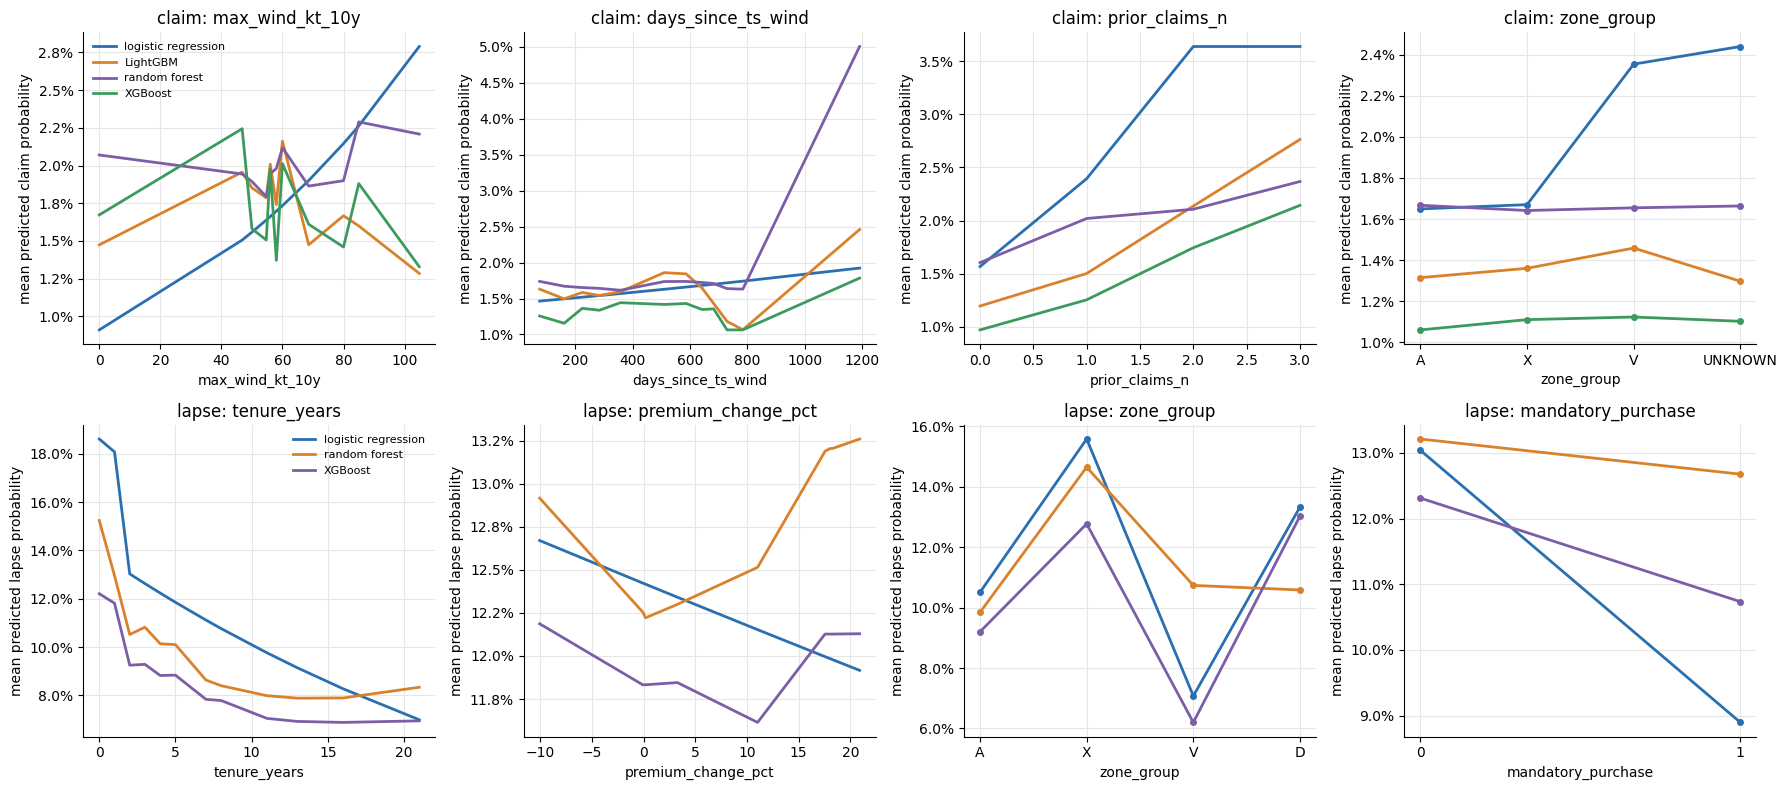

In [12]:
# Step 3.1 Partial dependence of the key features, every model of each target
PDP_FEATURES = {"claim": ["max_wind_kt_10y", "days_since_ts_wind", "prior_claims_n", "zone_group"],
                "lapse": ["tenure_years", "premium_change_pct", "zone_group", "mandatory_purchase"]}
PDP = {}
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for row, kind in zip(axes, ev.TARGETS):
    raw = SAMPLE[kind].iloc[:N_PDP].reset_index(drop=True)
    for ax, f in zip(row, PDP_FEATURES[kind]):
        t0 = time.time()
        pdp = ex.partial_dependence(registry[kind], raw, f)
        PDP[(kind, f)] = pdp
        categorical = ex._kinds().get(f) in ("cat", "flag")
        x = np.arange(len(pdp)) if categorical else pdp.index.to_numpy(dtype=float)
        for i, name in enumerate(registry[kind]):
            if name in pdp:
                ax.plot(x, pdp[name], marker="o" if categorical else None, markersize=4,
                        label=NAMES[name], **ev.model_style(name, i + 1))
        if categorical:
            ax.set_xticks(x, [str(v) for v in pdp.index], rotation=0)
        ax.set(title=f"{kind}: {f}", xlabel=f, ylabel=f"mean predicted {ev.TARGETS[kind]['event']} probability")
        ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
        ev.style_axes(ax)
        print(f"{kind} {f}: {len(pdp)} values in {time.time() - t0:.0f} s")
    row[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / f"fig_{OUT}_partial_dependence.png", dpi=150)
plt.show()
pd.concat({f"{k}: {f}": v for (k, f), v in PDP.items()}).to_csv(OUT_DIR / f"{OUT}_partial_dependence.csv")

**What we found (Step 3.1)**

*Claims*
1. **Prior claims raise the predicted risk in every model,** step by step: from 0 to 3 earlier claims, the mean prediction goes from **1.6% to 3.6%** (logistic regression), 1.6% to 2.4% (random forest), 1.2% to 2.8% (LightGBM) and 1.0% to 2.1% (XGBoost).
2. **Maximum storm wind in the last 10 years:** the logistic regression rises steadily (0.9% with no storm wind to 2.8% at 105 kt). The tree models stay roughly **flat at 1.3–2.3%**: they take storm exposure from the other storm features (Step 2.2), so this one adds little on its own.
3. **Days since the last storm wind** (76 to 1,191 days, the 5th to 95th percentile): the logistic regression rises slowly (1.5% → 1.9%); the tree models stay **flat at about 1.1–1.9% up to two years**, with a dip for LightGBM and XGBoost near two years (about 1.1%), then **jump at about three years and more** (random forest **5.0%**, LightGBM 2.5%, XGBoost 1.8% at 1,191 days). Such a jump most likely marks **particular places** (where the last storm was long ago) rather than a real effect of time; it is the kind of pattern to check before trusting a single policy's explanation.
4. **Flood zone changes the claim prediction little once everything else is known:** zones A, X, V and UNKNOWN differ by less than 0.2 points for the tree models; only the logistic regression gives zone V a clearly higher risk (2.4% vs 1.7%). The other features (storm exposure, elevation, price) already carry the zone's risk.

*Lapse*

5. **Tenure is the strongest effect, and the first renewal is the cliff:** the random forest's mean prediction falls from **15.2%** for a new policy to 13.0% at one year, **10.5% at two years**, 8.4% at eight years and about 7.9% after 13 years. The logistic regression (18.6% → 7.0%) and XGBoost (12.2% → 6.9%) show the same shape.
6. **Flood zone:** zone X (outside the high-risk zones, rarely required by a lender) has the highest predicted lapse: **14.7%** for the random forest, against 9.9% in zone A and 10.7% in zone V.
7. **Mandatory purchase:** the logistic regression gives a large drop (13.0% → 8.9%), the trees a smaller one (random forest 13.2% → 12.7%, XGBoost 12.3% → 10.7%): in the trees, zone and other features already carry most of the lender requirement.
8. **Premium change:** almost **flat** in every model (random forest 12.3% at no change, 13.2% at +18–21%). Many policies sit at about **+18%**, the statutory cap on yearly increases for most policies, so the grid repeats values there.

### Section 4. Example explanations

#### 4.1 Individual policies
For the **primary model** of each target we explain three policy-years from the sample:

1. **High risk, and the event happened:** the highest-scored policy-year that had a claim (lapse);
2. **Low risk:** the lowest-scored policy-year;
3. **Surprising:** the policy-year that had a claim (lapse) but got the **lowest** score among those that did: what the model missed.

Each **waterfall** starts from the baseline (the average model output), adds the eight largest contributions (orange = pushes the risk up, blue = down) and the rest, and ends at the policy's prediction. The table under the charts gives the actual values of the features shown, so the explanation can be read in plain words.

The lapse random forest fills the missing values of seven features with random training values, and the draws depend on the rows scored together; the predictions here are therefore computed on this sample (they can differ by a percentage point or two from 08a's for the few rows with those values missing).

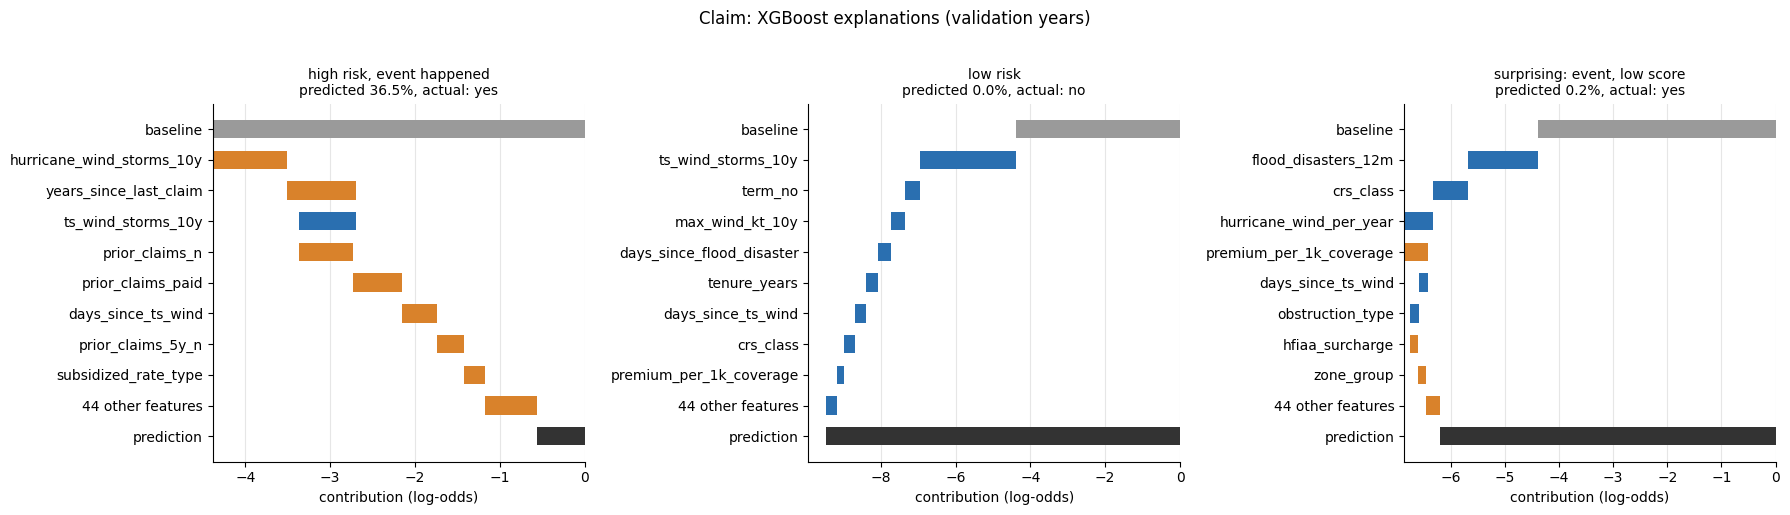

,"high risk, event happened",low risk,"surprising: event, low score"
crs_class (contribution),0.1768,-0.2887,-0.6298
crs_class (value),6,5,2
days_since_flood_disaster (contribution),0.2115,-0.346,0.0233
days_since_flood_disaster (value),360,47,64
days_since_ts_wind (contribution),0.4017,-0.295,-0.1761
days_since_ts_wind (value),3,99,358
flood_disasters_12m (contribution),-0.1768,0.1445,-1.305
flood_disasters_12m (value),1,2,5
hurricane_wind_per_year (contribution),0.0951,-0.1438,-0.5442
hurricane_wind_per_year (value),0.2515,0.06974,0


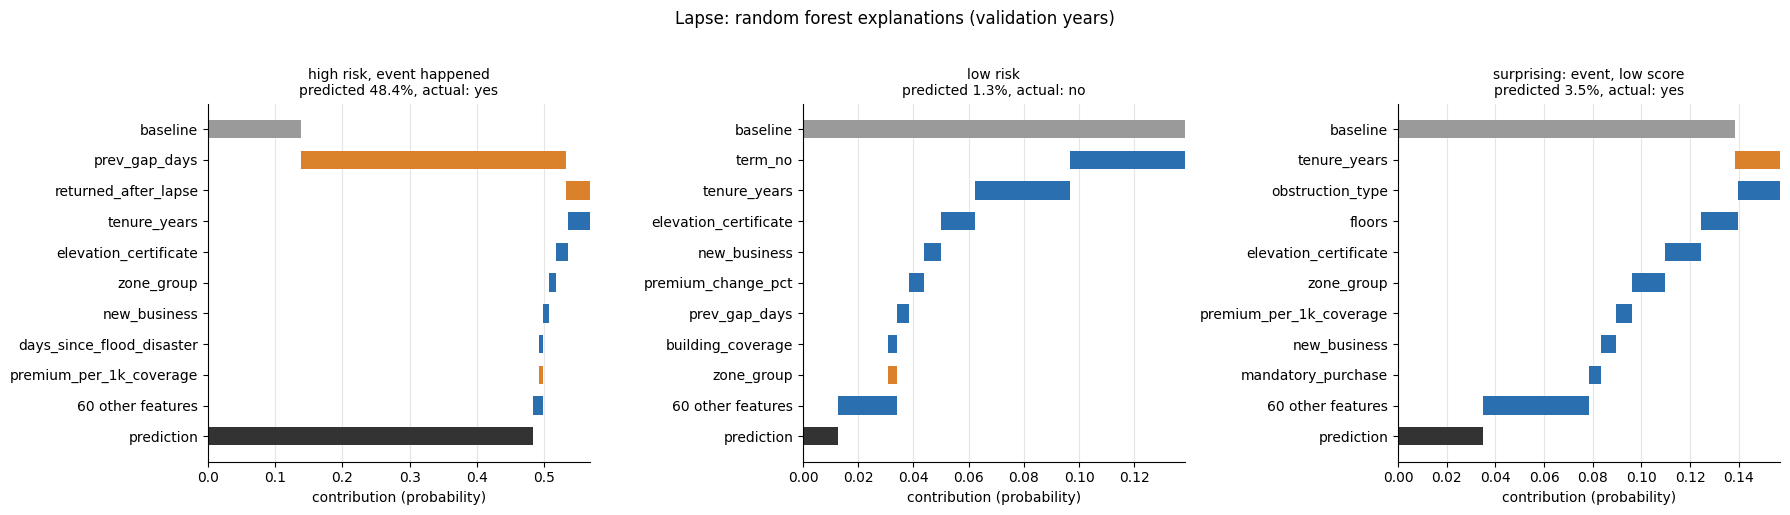

,"high risk, event happened",low risk,"surprising: event, low score"
elevation_certificate (contribution),-0.0176,-0.0121,-0.015
elevation_certificate (value),None,None,None
floors (contribution),-0.0034,-0.0031,-0.0154
floors (value),1,1,1
new_business (contribution),-0.0083,-0.0062,-0.0062
new_business (value),False,False,False
obstruction_type (contribution),0.0002,0.0001,-0.0171
obstruction_type (value),None,None,54
premium_change_pct (contribution),0.0003,-0.0055,0.0021
premium_change_pct (value),NaN,-4.931,10.89


In [6]:
# Step 4.1 Three example policy-years per target, explained by the primary model
EXAMPLES = {}
for kind in ev.TARGETS:
    name = PRIMARY[kind]
    r = CONTRIB[kind][name]
    y = r["raw"]["y"].to_numpy()
    p = r["pred"]
    events = np.flatnonzero(y == 1)
    picks = {"high risk, event happened": events[np.argmax(p[events])],
             "low risk": int(np.argmin(p)),
             "surprising: event, low score": events[np.argmin(p[events])]}
    EXAMPLES[kind] = picks
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, (label, i) in zip(axes, picks.items()):
        out = r["base"][i] + r["contrib"].iloc[i].sum()
        ex.plot_waterfall(ax, r["contrib"].iloc[i], r["base"][i], out, r["scale"],
                          f"{label}\npredicted {p[i]:.1%}, actual: {'yes' if y[i] else 'no'}")
    fig.suptitle(f"{kind.capitalize()}: {NAMES[name]} explanations (validation years)", y=1.02)
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"fig_{OUT}_{kind}_examples.png", dpi=150, bbox_inches="tight")
    plt.show()

    # The values behind the largest contributions, in plain columns
    shown = sorted({f for i in picks.values() for f in r["contrib"].iloc[i].abs().nlargest(6).index})
    table = pd.DataFrame({label: {f"{f} (value)": r["raw"].loc[i, f] for f in shown} |
                                 {f"{f} (contribution)": round(float(r["contrib"].iloc[i][f]), 4) for f in shown}
                          for label, i in picks.items()})
    display(table.sort_index())

**What we found (Step 4.1)**

*Claims (XGBoost)*
1. **High risk, claimed (predicted 36.5%):** a policy-year with **three earlier claims** ($38,400 paid), the last only half a year before the start, in a cell hit by **hurricane-force wind three times** in 10 years and by tropical-storm wind three days before the start. Each of these pushes the score up (hurricane storms +0.87, recent claim +0.82, prior claims +0.64 and +0.58 in log-odds): the explanation reads like an underwriter's reasoning.
2. **Low risk (predicted about 0.0%):** no earlier claims, 18 years of tenure, a CRS class 5 community, and a cell with many tropical-storm years in the last decade but no recent claim, which the model reads as low risk (−2.56 for `ts_wind_storms_10y`, Step 2.2: that feature has no single direction).
3. **Surprising, claimed with a low score (0.2%):** the largest push **down** comes from **five flood disaster declarations** in the county in the last 12 months (−1.31) a very good community rating (CRS class 2, −0.63) and no long-run hurricane rate at the cell (−0.54). A recent flood declaration should not lower the risk; the model seems to have learned that heavily declared counties had few *new* claims in the training years. This is a pattern to review (and a reason not to use the claim scores policy by policy without checks).

*Lapse (random forest)*

4. **High risk, lapsed (predicted 48.4%):** almost all of the score comes from **`prev_gap_days` = 36**: the policy came back after a 36-day gap since the previous term (+0.39 in probability). A policy that has already lapsed once is the clearest lapse signal.
5. **Low risk (1.3%):** the fourth term, seven years of tenure and a small premium decrease (−4.9%), each pushing the risk down.
6. **Surprising, lapsed with a low score (3.5%):** a one-floor zone A building with obstruction code 54, each lowering the risk slightly; the explanation shows no single strong signal, which is typical of the lapses a model cannot anticipate.

### Section 5. Business use

#### 5.1 Retention targeting
How the lapse model would choose which renewing policies get a **retention contact**, on **every** validation policy-year (the predictions saved by 08a):

- Each year, rank the policy-years by the model's lapse probability and contact the riskiest **10%, 20% or 30%** of **that year's** book (not a fixed cut-off from 2014–2020, which gives a shrinking list as lapse risk falls: 08a, Step 4.3).
- For each list size: the share of all lapses reached (recall), the lapse rate of the list (precision) and the **premium of the policies that lapsed** in the list (premium at risk reached), for the primary model, the other models and the segment rule.
- An **illustrative campaign**: if a contact keeps `SAVE_RATE` of the would-be lapsers at `COST_PER_CONTACT` each, how much premium is kept, net of cost? These two numbers are **assumptions**: replace them with real figures, or present the result as "if ... then ...".

**Recalibration (recommended in 08b):** every lapse model over-predicts 2023–24 (A/E 0.79 for the random forest). Recalibration fits a curve from the model's probability to the actual lapse rate (isotonic: it only goes up, so the **ranking and the lists above do not change**), and only the probability values move. We try it two ways:

- **(a) fitted on the test years (2021–2022)**, which we already used for tuning, applied to 2023–24;
- **(b) fitted on the latest full year (2023), checked on 2024**: how a yearly recalibration would run in production. The 2024 row is the honest check; the 2023 row is in-sample by construction.

If (a) barely helps, the shift happened after 2022 (Risk Rating 2.0), and the lesson is to recalibrate **every year on the latest data**, not once.

,year,model,list,contacts,lapse_rate_of_list,share_of_lapses,share_of_lapsed_premium,premium_kept_$M,cost_$M,net_$M
3,2023,random forest,riskiest 10%,"338,220",21.6%,21.1%,26.6%,8.0,6.8,+1.2
4,2023,random forest,riskiest 20%,"676,441",17.7%,34.7%,39.6%,11.9,13.5,-1.7
5,2023,random forest,riskiest 30%,"1,014,662",15.8%,46.3%,49.8%,14.9,20.3,-5.4
9,2023,segment rule,riskiest 10%,"338,220",16.8%,16.4%,19.5%,5.9,6.8,-0.9
10,2023,segment rule,riskiest 20%,"676,441",16.4%,32.1%,37.9%,11.4,13.5,-2.2
11,2023,segment rule,riskiest 30%,"1,014,662",14.0%,41.0%,45.8%,13.7,20.3,-6.6
15,2024,random forest,riskiest 10%,"223,907",21.4%,20.5%,24.9%,5.7,4.5,+1.2
16,2024,random forest,riskiest 20%,"447,814",17.6%,33.7%,38.2%,8.7,9.0,-0.2
17,2024,random forest,riskiest 30%,"671,721",15.6%,45.0%,49.1%,11.2,13.4,-2.2
21,2024,segment rule,riskiest 10%,"223,907",20.6%,19.8%,21.7%,5.0,4.5,+0.5


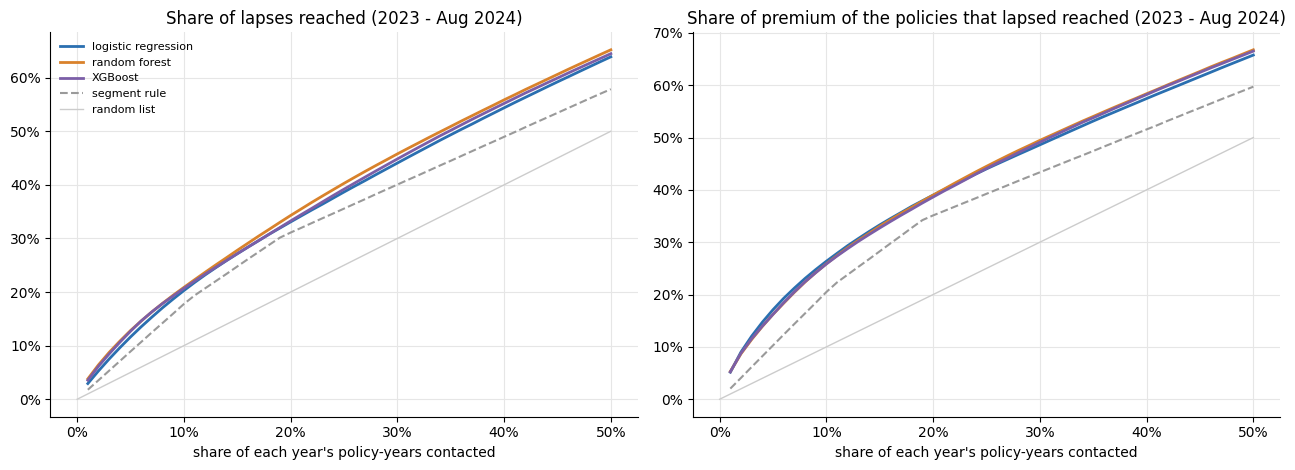

(a) fitted on 7,105,637 test policy-years (2021-2022); (b) fitted on 3,382,205 policy-years of 2023. Ranking unchanged: AUC 0.6270 (model) vs 0.6182 on 2024 after (b) (0.6182 before; ties can move it slightly)


,actual_lapses,expected_model,expected_a_test_fit,expected_b_2023_fit,actual_lapsed_premium,expected_premium_model,expected_premium_b_2023_fit,A/E model,A/E a_test_fit,A/E b_2023_fit,note
period_year,,,,,,,,,,,
2023,"345,398","442,873","445,397","345,398","299,722,422","415,735,948","324,887,975",0.780,0.775,1.000,2023: in-sample for (b)
2024,"233,448","288,949","289,235","225,135","228,387,184","303,720,652","236,269,063",0.808,0.807,1.037,2024: honest check for (b)
all,"578,846","731,822","734,633","570,533","528,109,606","719,456,600","561,157,038",0.791,0.788,1.015,


In [7]:
# Step 5.1 Retention lists on every validation policy-year: lapses and premium reached, and an illustrative campaign
SAVE_RATE = 0.10           # ASSUMPTION: share of contacted would-be lapsers kept by a retention contact
COST_PER_CONTACT = 20.0    # ASSUMPTION: US$ per contact
SHARES = [0.10, 0.20, 0.30]

kind = "lapse"
cols = {**{NAMES[n]: f"p_{n}" for n in registry[kind]}, "segment rule": "p_segment"}
lp = pd.read_parquet(PRED_DIR / "eval_valid_lapse_predictions.parquet", columns=["period_id", "period_year", "y", *cols.values()])
prem = con.sql("""SELECT period_id, CASE WHEN premium > 0 THEN premium ELSE 0 END AS premium
                  FROM feats WHERE in_pop_lapse AND split = 'valid'""").df()
lp = lp.merge(prem, on="period_id", how="left")
lp["premium"] = lp["premium"].fillna(0)
lp["lapsed_premium"] = lp["y"] * lp["premium"]
rng = np.random.default_rng(SEED)
lp["tie"] = rng.random(len(lp))                                     # random order inside ties (the segment rule)

rows = []
for (year, g), (label, col) in [((y, g), lc) for y, g in lp.groupby("period_year") for lc in cols.items()]:
    g = g.sort_values([col, "tie"], ascending=[False, True])
    for s in SHARES:
        top = g.head(int(round(s * len(g))))
        kept = SAVE_RATE * top["lapsed_premium"].sum()
        cost = COST_PER_CONTACT * len(top)
        rows.append({"year": year, "model": label, "list": f"riskiest {s:.0%}", "contacts": len(top),
                     "lapse_rate_of_list": top["y"].mean(), "share_of_lapses": top["y"].sum() / g["y"].sum(),
                     "share_of_lapsed_premium": top["lapsed_premium"].sum() / g["lapsed_premium"].sum(),
                     "premium_kept_$M": kept / 1e6, "cost_$M": cost / 1e6, "net_$M": (kept - cost) / 1e6})
RETENTION = pd.DataFrame(rows)
RETENTION.to_csv(OUT_DIR / f"{OUT}_lapse_retention_lists.csv", index=False)
display(RETENTION[RETENTION["model"].isin([NAMES[PRIMARY[kind]], "segment rule"])]
        .style.format({"contacts": "{:,}", "lapse_rate_of_list": "{:.1%}", "share_of_lapses": "{:.1%}",
                       "share_of_lapsed_premium": "{:.1%}", "premium_kept_$M": "{:,.1f}", "cost_$M": "{:,.1f}",
                       "net_$M": "{:+,.1f}"}))

# Capture curves: share of lapses and of lapsed premium reached, by share of each year's book contacted
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
grid = np.linspace(0.01, 0.5, 50)
for i, (label, col) in enumerate(cols.items()):
    g = lp.sort_values(["period_year", col, "tie"], ascending=[True, False, True])
    g["rank"] = g.groupby("period_year").cumcount() / g.groupby("period_year")["y"].transform("size")
    for ax, what in zip(axes, ["y", "lapsed_premium"]):
        reached = [g.loc[g["rank"] < s, what].sum() / g[what].sum() for s in grid]
        style = dict(color=ev.GREY, linewidth=1.5, linestyle="--") if label == "segment rule" else ev.model_style(label, i + 1)
        ax.plot(grid, reached, label=label, **style)
for ax, what in zip(axes, ["lapses", "premium of the policies that lapsed"]):
    ax.plot([0, 0.5], [0, 0.5], color="#cccccc", linewidth=1, label="random list")
    ax.set(title=f"Share of {what} reached (2023 - Aug 2024)", xlabel="share of each year's policy-years contacted")
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ev.style_axes(ax)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / f"fig_{OUT}_lapse_retention.png", dpi=150)
plt.show()

# Recalibration of the primary lapse model: (a) fitted on the test years, (b) fitted on 2023 and checked on 2024
col = f"p_{PRIMARY[kind]}"
saved_test = ev.load_saved_test(PRED_DIR, {PRIMARY[kind]: registry[kind][PRIMARY[kind]]})
iso = lambda: IsotonicRegression(out_of_bounds="clip", y_min=1e-4, y_max=1 - 1e-4)
recal_test = iso().fit(saved_test[col], saved_test["y"])                       # (a) 2021-2022
in_2023 = lp["period_year"] == 2023
recal_2023 = iso().fit(lp.loc[in_2023, col], lp.loc[in_2023, "y"])              # (b) 2023 only
lp["p_recal_test"] = recal_test.predict(lp[col])
lp["p_recal_2023"] = recal_2023.predict(lp[col])

calib = lp.groupby("period_year").agg(actual_lapses=("y", "sum"), expected_model=(col, "sum"),
                                      expected_a_test_fit=("p_recal_test", "sum"), expected_b_2023_fit=("p_recal_2023", "sum"),
                                      actual_lapsed_premium=("lapsed_premium", "sum"))
for name, c in [("model", col), ("b_2023_fit", "p_recal_2023")]:
    calib[f"expected_premium_{name}"] = (lp[c] * lp["premium"]).groupby(lp["period_year"]).sum()
calib.loc["all"] = calib.sum()
for name in ["model", "a_test_fit", "b_2023_fit"]:
    calib[f"A/E {name}"] = calib["actual_lapses"] / calib[f"expected_{name}"]
calib["note"] = ["2023: in-sample for (b)", "2024: honest check for (b)", ""][: len(calib)]
calib.to_csv(OUT_DIR / f"{OUT}_lapse_recalibration.csv")
print(f"(a) fitted on {len(saved_test):,} test policy-years (2021-2022); (b) fitted on {in_2023.sum():,} policy-years of 2023. "
      f"Ranking unchanged: AUC {roc_auc_score(lp['y'], lp[col]):.4f} (model) vs "
      f"{roc_auc_score(lp.loc[~in_2023, 'y'], lp.loc[~in_2023, 'p_recal_2023']):.4f} on 2024 after (b) "
      f"({roc_auc_score(lp.loc[~in_2023, 'y'], lp.loc[~in_2023, col]):.4f} before; ties can move it slightly)")
display(calib.style.format("{:,.0f}", subset=[c for c in calib.columns if c.startswith(("actual", "expected"))])
             .format("{:.3f}", subset=[c for c in calib.columns if c.startswith("A/E")]))

**What we found (Step 5.1)**

1. **Contacting the riskiest 20% of each year's book reaches about a third of the lapses** with the random forest (34.7% in 2023, 33.7% in 2024) and **about 40% of the premium of the policies that lapsed** (39.6%, 38.2%). The riskiest 10% reach 21% of lapses and 25–27% of lapsed premium; the riskiest 30%, 45–46% and about 50%.
2. **The three models are almost tied** (within about 1 point at every list size; the logistic regression is as good as the trees on lapsed premium), and **all beat the segment rule**, most at the smaller lists: at 10% in 2024, 20.5% of lapses (random forest) vs 19.8% (segment rule), and **24.9% vs 21.8% of lapsed premium**; at 20% in 2024, 33.7% vs 29.6% of lapses.
3. **The campaign pays only with a short list** under our assumptions (10% of contacted would-be lapsers kept, $20 a contact): contacting the riskiest **10%** nets about **+$1.2M a year** (random forest; +$1.2M to +$1.4M for the other models), while 20% roughly breaks even or loses (−$1.7M in 2023, −$0.2M in 2024) and 30% loses $2–5M. A smaller, sharper list is better; the result depends directly on the two assumptions.
4. **Recalibration must use recent data:** a curve fitted on 2021–2022 leaves the A/E unchanged (0.78 in 2023, 0.81 in 2024), because the model was still well calibrated then and the shift came later. A curve fitted on **2023** brings **2024 to A/E 1.04** (from 0.81) and the expected premium of lapsing policies to **$236M against $228M actual** (from $304M), with the ranking unchanged. A **yearly recalibration on the latest full year** is enough to keep the lapse probabilities usable.

#### 5.2 Pricing adequacy
Where do the claim scores suggest premiums are **too low or too high for the risk**? We have no claim **amounts** in the modeling data, so this is a **frequency** view: we compare, by risk group, how often policy-years claim with how much they pay per $1,000 of cover.

- Every validation policy-year is ranked by the primary claim model and cut into 10 groups (decile 10 = riskiest). For each group: the **actual claim rate**, the average premium and the median **price per $1,000 of coverage** (`premium_per_1k_coverage`).
- Both are turned into an **index** (group ÷ all policy-years): a claim index of 3.0 means three times the average claim frequency; a price index of 1.2 means 20% above the average price.
- **Price index ÷ claim index** shows whether the price follows the risk: well below 1 in the riskiest groups means their price rises much less than their claim frequency (possibly under-priced for frequency); above 1 in the safest groups means they pay more than their frequency suggests.

The same comparison by flood zone group is shown under the chart. All validation policy-years are rated under Risk Rating 2.0.

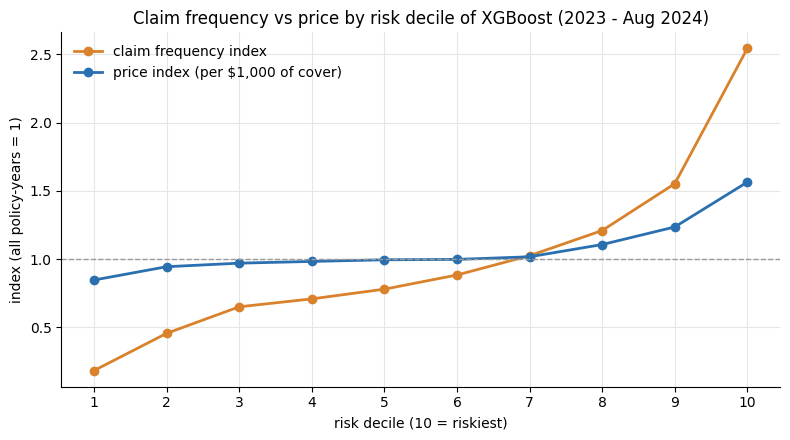

,policy_years,claims,claim_rate,predicted,avg_premium,median_rate_per_1k,claim_index,price_index,price_over_claim
decile,,,,,,,,,
1,"572,479","1,647",0.29%,0.07%,$692,$1.76,0.18,0.85,4.61
2,"572,479","4,090",0.71%,0.16%,$794,$1.97,0.46,0.95,2.07
3,"572,479","5,831",1.02%,0.25%,$840,$2.02,0.65,0.97,1.49
4,"572,479","6,351",1.11%,0.36%,$865,$2.05,0.71,0.98,1.39
5,"572,479","6,987",1.22%,0.48%,$876,$2.07,0.78,1.00,1.28
6,"572,479","7,917",1.38%,0.63%,$898,$2.08,0.88,1.00,1.13
7,"572,479","9,183",1.60%,0.82%,$928,$2.12,1.03,1.02,0.99
8,"572,479","10,833",1.89%,1.11%,$968,$2.30,1.21,1.11,0.92
9,"572,479","13,903",2.43%,1.64%,"$1,059",$2.57,1.55,1.24,0.80


,policy_years,claims,claim_rate,predicted,avg_premium,median_rate_per_1k,claim_index,price_index,price_over_claim
zone_group,,,,,,,,,
V,"89,322","3,163",3.54%,2.12%,"$1,790",$4.37,2.26,2.10,0.93
A,"3,033,296","74,213",2.45%,1.30%,"$1,126",$2.99,1.56,1.44,0.92
D,"2,515",21,0.83%,0.77%,"$1,366",$4.28,0.53,2.06,3.85
X,"2,599,657","12,119",0.47%,0.81%,$651,$1.76,0.30,0.85,2.84


In [8]:
# Step 5.2 Claim frequency vs price by risk decile of the primary claim model (every validation policy-year)
kind = "claim"
col = f"p_{PRIMARY[kind]}"
cp = pd.read_parquet(PRED_DIR / "eval_valid_claim_predictions.parquet", columns=["period_id", "y", "zone_group", col])
price = con.sql("""SELECT period_id,
                          CASE WHEN premium > 0 THEN premium END AS premium,
                          CASE WHEN premium_per_1k_coverage > 0 THEN premium_per_1k_coverage END AS rate_per_1k
                   FROM feats WHERE in_pop_claim AND split = 'valid'""").df()
cp = cp.merge(price, on="period_id", how="left")
cp["decile"] = pd.qcut(cp[col].rank(method="first"), 10, labels=range(1, 11)).astype(int)

def adequacy(frame, by):
    t = frame.groupby(by).agg(policy_years=("y", "size"), claims=("y", "sum"), claim_rate=("y", "mean"),
                              predicted=(col, "mean"), avg_premium=("premium", "mean"), median_rate_per_1k=("rate_per_1k", "median"))
    t["claim_index"] = t["claim_rate"] / frame["y"].mean()
    t["price_index"] = t["median_rate_per_1k"] / frame["rate_per_1k"].median()
    t["price_over_claim"] = t["price_index"] / t["claim_index"]
    return t

PRICING = adequacy(cp, "decile")
PRICING_ZONE = adequacy(cp, "zone_group").sort_values("claim_index", ascending=False)
PRICING.to_csv(OUT_DIR / f"{OUT}_claim_pricing_by_decile.csv")
PRICING_ZONE.to_csv(OUT_DIR / f"{OUT}_claim_pricing_by_zone.csv")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(PRICING.index, PRICING["claim_index"], marker="o", color="#d9822b", linewidth=2, label="claim frequency index")
ax.plot(PRICING.index, PRICING["price_index"], marker="o", color="#2a6fb0", linewidth=2, label="price index (per $1,000 of cover)")
ax.axhline(1, color="#9a9a9a", linewidth=1, linestyle="--")
ax.set(title=f"Claim frequency vs price by risk decile of {NAMES[PRIMARY[kind]]} (2023 - Aug 2024)",
       xlabel="risk decile (10 = riskiest)", ylabel="index (all policy-years = 1)")
ax.set_xticks(range(1, 11)); ax.legend(frameon=False); ev.style_axes(ax)
plt.tight_layout()
plt.savefig(OUT_DIR / f"fig_{OUT}_claim_pricing.png", dpi=150)
plt.show()
fmt = {"policy_years": "{:,}", "claims": "{:,}", "claim_rate": "{:.2%}", "predicted": "{:.2%}", "avg_premium": "${:,.0f}",
       "median_rate_per_1k": "${:,.2f}", "claim_index": "{:.2f}", "price_index": "{:.2f}", "price_over_claim": "{:.2f}"}
display(PRICING.style.format(fmt))
display(PRICING_ZONE.style.format(fmt))

**What we found (Step 5.2)**

1. **Price follows claim frequency only weakly across the model's risk deciles.** The riskiest 10% of policy-years claim **2.5× as often** as average (3.98%) but pay **1.6×** the average price per $1,000 of cover (price ÷ claim index 0.62); the safest 10% claim at **0.18×** the average (0.29%) and pay **0.85×** (ratio 4.6). The two lines cross at decile 7.
2. **By flood zone, price is closer to frequency:** zones V and A pay about what their claim frequency suggests (ratios 0.93 and 0.92), while zone X pays **2.8×** its relative frequency (0.47% claims, 0.85× the average price). So the model finds **differences in claim risk within zones** that the price does not reflect, and zone X appears to pay more than its frequency.
3. **This is a frequency view only:** a higher price per $1,000 can be justified by larger losses per claim, which we cannot see (no claim amounts). The result points to where a **pricing review with loss data** would be worth doing, not to a pricing error.

### Section 6. Limitations and data caveats

#### 6.1 Limitations
**Data and linkage**
- **No policy ID in the public data.** Terms are linked into policies with a reconstructed key (notebook 03); some links are wrong or missed, which adds noise to tenure, history and the lapse target.
- **Redacted locations and demographics.** FEMA rounds latitude and longitude to 0.1° and removes personal data, so local flood exposure and the policyholder's circumstances are only approximated (census tract ACS figures, with a later snapshot used for earlier years).
- **Censoring.** Policy-years whose outcome was not yet observable at the data cutoff are excluded, so the latest months carry less weight; the storm data end in November 2024.
- **Undocumented codes** found during cleaning (notebook 02) were mapped to "unknown" or flagged rather than guessed.

**Modeling**
- **Storms during the term drive claims but are unknown at the start of the policy.** No start-of-policy model can predict a hurricane season, so claim probabilities swing from year to year (08b: A/E 0.58 in 2023, 1.37 in 2024).
- **Program change.** Risk Rating 2.0 (April 2022) changed premiums and the price features sharply (08b, PSI 9–15); the models learned on 2014–2020 and over-predict lapse in 2023–24.
- **Tree models fit the training years closely** (training ROC-AUC 0.91–0.94 for the claim trees, 0.77 for the lapse random forest, against 0.62–0.74 out of time); the out-of-time results are the honest measure.
- **The claim tree models were trained on every claim plus 10% of the other policy-years, weighted back**, and tuned for recall in the riskiest 10%; their ranking is the strength, and the XGBoost / LightGBM probabilities are not well calibrated (08b).
- **The lapse random forest's random fill** of seven features (to stop the trees spotting missing values) depends on the rows scored together, so a policy with those values missing can score slightly differently in another batch.
- **Some tree patterns are counterintuitive** (Steps 3.1, 4.1): recent flood declarations lowering a claim score, a jump in claim risk about three years after the last storm wind. They most likely stand for particular places or periods in the training years, and show why a single policy's explanation should be checked.
- **Explanations are not causes.** Importance and contributions describe what the models rely on; a feature can matter because it stands for something else (for example, flood zone for the lender requirement).
- **No claim amounts.** The pricing view (Step 5.2) compares claim frequency with price, not expected losses with premium.

The table below summarizes each model as saved.

In [9]:
# Step 6.1 Model card: what each final model is, what it was trained on, and how it did on the validation years
cards = []
for kind in ev.TARGETS:
    b = bench[kind][bench[kind]["scope"].str.startswith("OOT2")].set_index("model")
    for name, m in registry[kind].items():
        run = m.get("run", {})
        cards.append({"target": kind, "model": NAMES[name], "file": f"{name}.joblib", "primary": name == PRIMARY[kind],
                      "type": getattr(m["model"], "type_name", type(m["model"]).__name__), "features": len(m["features"]),
                      "trained_on": run.get("train_split", run.get("training_data", "?")),
                      "validation_auc": b.loc[name, "roc_auc"] if name in b.index else np.nan})
MODEL_CARD = pd.DataFrame(cards)
MODEL_CARD.to_csv(OUT_DIR / f"{OUT}_model_card.csv", index=False)
with pd.option_context("display.max_colwidth", 90):
    display(MODEL_CARD.style.format({"validation_auc": "{:.3f}"}))

,target,model,file,primary,type,features,trained_on,validation_auc
0,claim,logistic regression,claim_baseline_logreg.joblib,False,SGDClassifier,52,"train (2014-2020), every row, in chunks",0.650
1,claim,LightGBM,claim_lgbm.joblib,False,LightGBM Booster,52,"train (2014-2020): every claim + 10% of the other policy-years, weighted back",0.709
2,claim,random forest,claim_rf.joblib,False,RandomForestClassifier,52,"train (2014-2020): every claim + 10% of the other policy-years, weighted back",0.736
3,claim,XGBoost,claim_xgb.joblib,True,XGBoost Booster,52,"train (2014-2020): every claim + 10% of the other policy-years, weighted back",0.669
4,lapse,logistic regression,lapse_baseline_logreg.joblib,False,SGDClassifier,68,"train (2014-2020), every row, in chunks",0.615
5,lapse,random forest,lapse_rf.joblib,True,RandomForestClassifier,68,"train (2014-2020), all 26,758,825 rows, read in 06b's 28 chunks (2 at a time): 14 trees per group x 14 groups = 196 trees, each on 25% of its group",0.627
6,lapse,XGBoost,lapse_xgb.joblib,False,XGBClassifier,68,"all 26,758,825 training rows, 06b's 28 chunks streamed into a QuantileDMatrix",0.619


### Section 7. Conclusions and recommendations

#### 7.1 Conclusions
The table below gathers the headline validation results of 08a/08b and the top drivers found here, one row per model.

*Our conclusions (evaluation results from 08a/08b; drivers and business use from this notebook):*

**Lapse**
1. **The random forest is the best lapse model** in both out-of-time periods (validation ROC-AUC 0.627; 34.3% of lapses reached when contacting the riskiest 20%, against 31.0% for the segment rule), and the gain over the other models is real but small.
2. **What drives lapse (Section 2):** **tenure** above all (shuffling it costs the random forest 0.098 of AUC), then **flood zone** and the **term number**; the three models agree. Longer tenure, a primary residence and larger building coverage lower the risk; a first-year policy, zone X and a higher price per $1,000 raise it. A policy that **returned after a gap** is the clearest single lapse signal (Step 4.1). The latest **premium change** matters little.
3. **How the risk changes (Section 3):** predicted lapse falls from about 15% for a new policy to 10.5% at two years and 8% after eight years: the **first renewal** is where most policies are lost. Zone X policies are predicted to lapse at about 15%, against 10–11% in zones A and V.
4. **Business value (Section 5.1):** contacting the riskiest 20% of each year's renewals reaches about a third of the lapses and 40% of the premium at risk; under our illustrative assumptions only the **riskiest 10%** pays for itself (about +$1.2M a year). Recalibrating every year on the latest year fixes the over-prediction (2024 A/E 0.81 → 1.04).

**Claims**

5. **The tree models rank claims better than the logistic regression on 2023–24** (validation ROC-AUC 0.67–0.74 vs 0.65), but their order changes between periods and their gain over a zone × earlier-claim rule is small; claims follow storms that no start-of-policy model can see (08b: A/E 0.58 in 2023, 1.37 in 2024).
6. **What drives claims (Section 2):** for ranking 2023–24, the **price per $1,000 of cover** and **recent flood disaster declarations**; within each score, **storm exposure** (days since storm wind, storm counts, long-run hurricane rate), then the community rating, building age and **earlier claims** (0 → 3 prior claims doubles to triples the prediction). The logistic regression's straight-line relationships partly reverse in 2023–24. Some tree patterns are counterintuitive (recent flood declarations lowering a score, a jump at three years since the last storm), so **single-policy claim explanations need checking** before use.
7. **Pricing adequacy (Section 5.2):** the price per $1,000 rises much less than claim frequency across the model's risk deciles (riskiest 10%: 2.5× the frequency, 1.6× the price), while by zone the price roughly follows frequency for A and V and is high for X. With no loss amounts this is a **frequency signal for a pricing review**, not proof of under-pricing.


In [10]:
# Step 7.1 Headline table: validation results (08a/08b) and the top 3 drivers (Step 2.1) of every model
prob = {kind: pd.read_csv(REPORTS / f"eval_valid_{kind}_probability.csv") for kind in ev.TARGETS}
conf = {kind: pd.read_csv(REPORTS / f"eval_valid_{kind}_confusion.csv") for kind in ev.TARGETS}
rows = []
for kind in ev.TARGETS:
    main = f"riskiest {ev.TARGETS[kind]['main_share']:.0%} in train"
    for name in registry[kind]:
        b = bench[kind][(bench[kind]["model"] == name) & bench[kind]["scope"].str.startswith("OOT2")].iloc[0]
        c = conf[kind][(conf[kind]["model"] == name) & (conf[kind]["rule"] == main)].iloc[0]
        pr = prob[kind][(prob[kind]["model"] == name) & prob[kind]["scope"].str.startswith("OOT2")].iloc[0]
        rows.append({"target": kind, "model": NAMES[name], "primary": name == PRIMARY[kind], "roc_auc": b["roc_auc"],
                     "main rule": main, "flagged": c["flagged_share"], "recall": c["recall"], "precision": c["precision"],
                     "lift": c["lift"], "log_loss_skill": pr["log_loss_skill"], "A/E": pr["a_to_e"],
                     "top 3 drivers": ", ".join(IMPORTANCE[kind][name].sort_values(ascending=False).head(3).index)})
HEADLINE = pd.DataFrame(rows)
HEADLINE.to_csv(OUT_DIR / f"{OUT}_headline.csv", index=False)
with pd.option_context("display.max_colwidth", 80):
    display(HEADLINE.style.format({"roc_auc": "{:.3f}", "flagged": "{:.1%}", "recall": "{:.1%}", "precision": "{:.1%}",
                                   "lift": "{:.2f}", "log_loss_skill": "{:+.1%}", "A/E": "{:.2f}"}))

,target,model,primary,roc_auc,main rule,flagged,recall,precision,lift,log_loss_skill,A/E,top 3 drivers
0,claim,logistic regression,False,0.650,riskiest 10% in train,14.8%,28.3%,3.0%,1.91,+3.0%,0.91,"post_firm, max_wind_kt_10y, prev_gap_days"
1,claim,LightGBM,False,0.709,riskiest 10% in train,14.3%,35.5%,3.9%,2.48,+1.1%,1.17,"premium_per_1k_coverage, flood_disasters_12m, building_age"
2,claim,random forest,False,0.736,riskiest 10% in train,16.3%,40.9%,3.9%,2.50,+5.8%,0.92,"premium_per_1k_coverage, flood_disasters_12m, ts_wind_storms_10y"
3,claim,XGBoost,True,0.669,riskiest 10% in train,9.6%,24.6%,4.0%,2.58,-1.8%,1.43,"premium_per_1k_coverage, flood_disasters_12m, ts_wind_storms_10y"
4,lapse,logistic regression,False,0.615,riskiest 20% in train,16.8%,29.4%,18.0%,1.74,+1.7%,0.84,"zone_group, tenure_years, elevated_building"
5,lapse,random forest,True,0.627,riskiest 20% in train,13.0%,25.1%,19.9%,1.93,+3.6%,0.79,"tenure_years, zone_group, term_no"
6,lapse,XGBoost,False,0.619,riskiest 20% in train,12.9%,24.5%,19.6%,1.90,+3.1%,0.87,"tenure_years, zone_group, term_no"


#### 7.2 Recommendations and next steps
**For the insurer**
1. **Lapse:** use the **random forest** to rank each year's renewals and contact the riskiest 10% (the list that paid for itself under our assumptions; up to 20% if a contact costs less or saves more, Step 5.1); act **before the renewal date**, since almost every lapse is a non-renewal (08b, Step 2.5). **Recalibrate** the probabilities **every year on the latest full year** before using them for expected lapses or premium at risk (Step 5.1: a curve fitted on older years does not carry over).
2. **Claims:** use a tree model to **rank** policy-years for underwriting review or mitigation outreach; use the **random forest or logistic regression** (not XGBoost) when probabilities are needed, and add a **storm / catastrophe overlay** for expected claims, because storms during the term drive the year-to-year swings.
3. **Pricing:** review the riskiest deciles, where the price per $1,000 rises much less than claim frequency, and zone X, which pays more than its frequency (Step 5.2), adding claim amounts before drawing pricing conclusions.
4. **Check claim explanations before using them for single policies:** some tree patterns are counterintuitive (Steps 3.1, 4.1).

**For the models**

5. **Refit on 2014–2023** so the models learn the post-Risk Rating 2.0 behaviour, keeping 2024 as a fresh check.
6. **Monitor quarterly** with the rules of 08b (score and feature PSI against the same calendar quarter, A/E with a 4-quarter rolling window for claims), and recalibrate or retrain when they fire.
7. **Next improvements:** claim severity (to move from frequency to expected loss), a stable random fill for the lapse random forest (keyed on the policy-year, like the XGBoost notebook), and better linkage if a policy identifier becomes available.

In [11]:
# Step 7.2 Save a record of this run (the tables and figures were saved step by step)
run = {"split": SPLIT, "evaluated": ev.EVAL_NAMES[SPLIT], "saved_at": pd.Timestamp.now().isoformat(timespec="seconds"),
       "primary": PRIMARY, "models": {k: list(v) for k, v in registry.items()},
       "rows": {"importance": N_IMPORTANCE, "contributions": N_CONTRIB, "partial_dependence": N_PDP}, "seed": SEED,
       "assumptions": {"save_rate": SAVE_RATE, "cost_per_contact": COST_PER_CONTACT},
       "methods": {"importance": "drop in ROC-AUC, one shuffle per feature",
                   "contributions": "XGBoost/LightGBM TreeSHAP; random forest path decomposition; logistic regression coef x (value - mean)",
                   "partial_dependence": "mean probability with the feature set for every sampled row"}}
(OUT_DIR / f"{OUT}_run.json").write_text(json.dumps(run, indent=2, default=str))
saved = sorted(p.name for p in OUT_DIR.glob(f"*{OUT}*"))
print(f"{len(saved)} files saved in {OUT_DIR.relative_to(ROOT)}:"); print("\n".join(saved))

20 files saved in reports:
explain_valid_claim_contributions.csv
explain_valid_claim_permutation_importance.csv
explain_valid_claim_pricing_by_decile.csv
explain_valid_claim_pricing_by_zone.csv
explain_valid_headline.csv
explain_valid_lapse_contributions.csv
explain_valid_lapse_permutation_importance.csv
explain_valid_lapse_recalibration.csv
explain_valid_lapse_retention_lists.csv
explain_valid_model_card.csv
explain_valid_partial_dependence.csv
explain_valid_run.json
fig_explain_valid_claim_contributions.png
fig_explain_valid_claim_examples.png
fig_explain_valid_claim_pricing.png
fig_explain_valid_lapse_contributions.png
fig_explain_valid_lapse_examples.png
fig_explain_valid_lapse_retention.png
fig_explain_valid_partial_dependence.png
fig_explain_valid_permutation_importance.png
